In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import numpy as np
from matplotlib import cm


Dataset shape: (79068, 2)

First 5 rows:
                                           file_name  \
0  drug-female-9c34a81d-dc2f-4cb9-87ec-7675719ab8...   
1  drug-female-2fb0837b-3ec7-4c0b-9c04-9a07f0215e...   
2  drug-brand-en-us-male-78582a33-6aa4-4084-b2ce-...   
3  drug-male-29c9cfbe-deb3-4eef-9571-32700cb0a5d4...   
4  drug-brand-en-us-male-4288bb3e-209f-4d68-9282-...   

                                       transcription  
0  Have you picked up your prescription of CLOTTO...  
1  Encorafenib is a targeted therapy medication u...  
2   Make sure to follow the recommended dosage wh...  
3  YOCIT is a prescription medication commonly us...  
4   Make sure to follow your doctor's instruction...  

Missing values:
file_name        0
transcription    0
dtype: int64

Files containing 'male': 39637
Files containing 'female': 39431
Files containing both 'male' and 'female': 0
Files containing neither 'male' nor 'female': 0

No files found containing both 'male' and 'female'.

Gender Distr

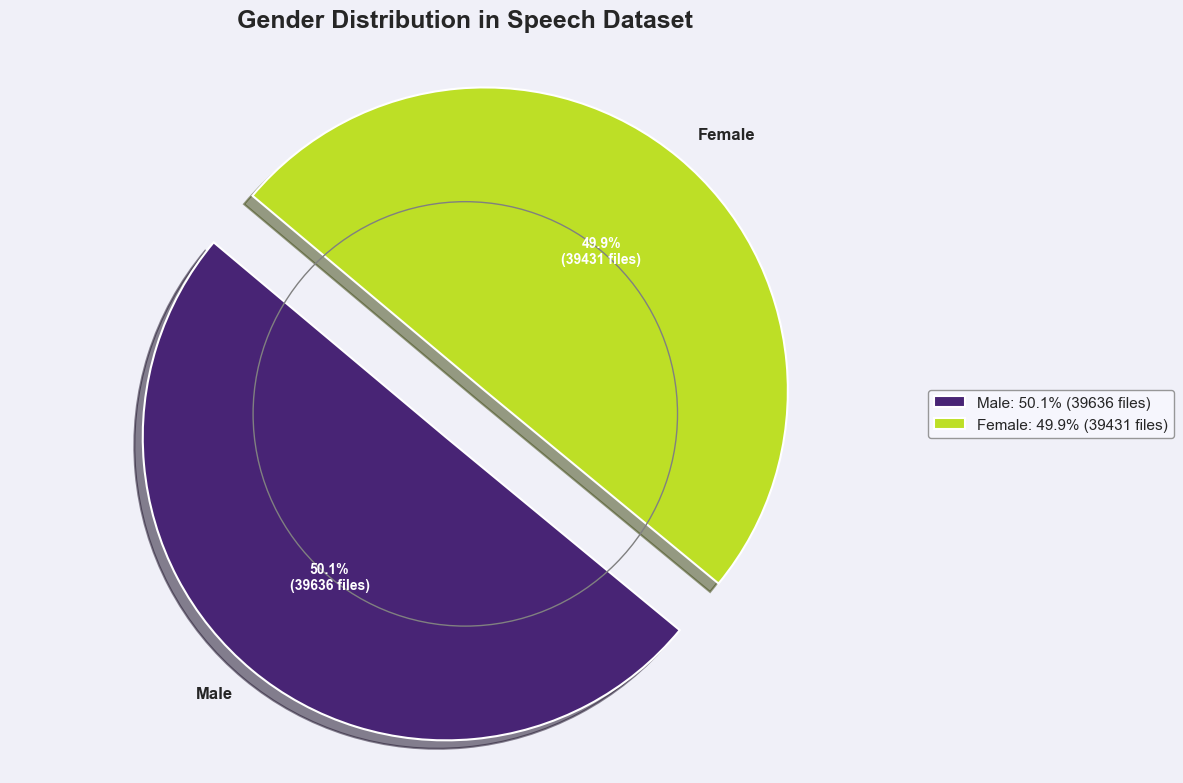


Transcription Statistics:
       transcription_length    word_count
count          79068.000000  79068.000000
mean              89.500329     13.115963
std               20.026640      2.865155
min               35.000000      4.000000
25%               75.000000     11.000000
50%               87.000000     13.000000
75%              102.000000     15.000000
max              276.000000     34.000000


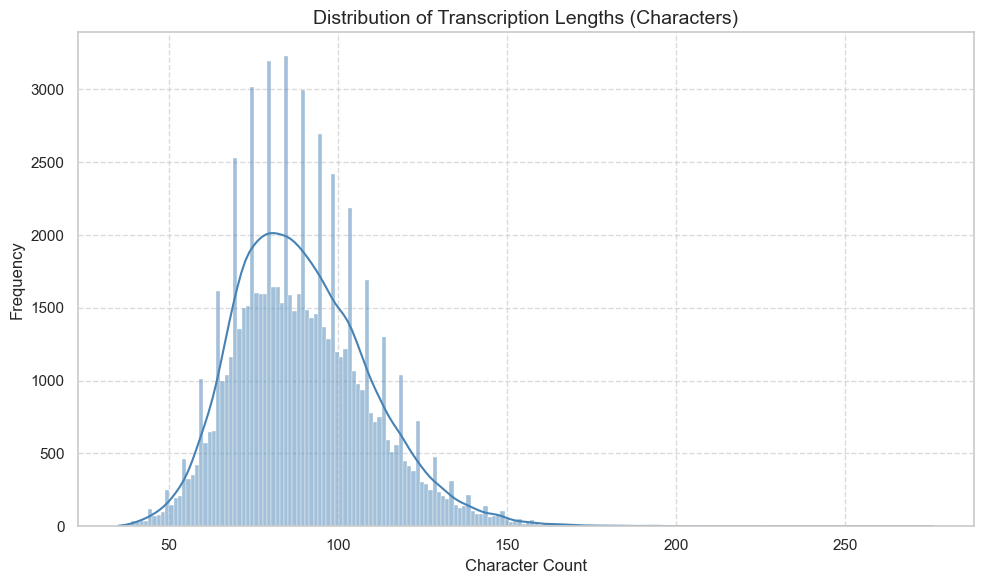

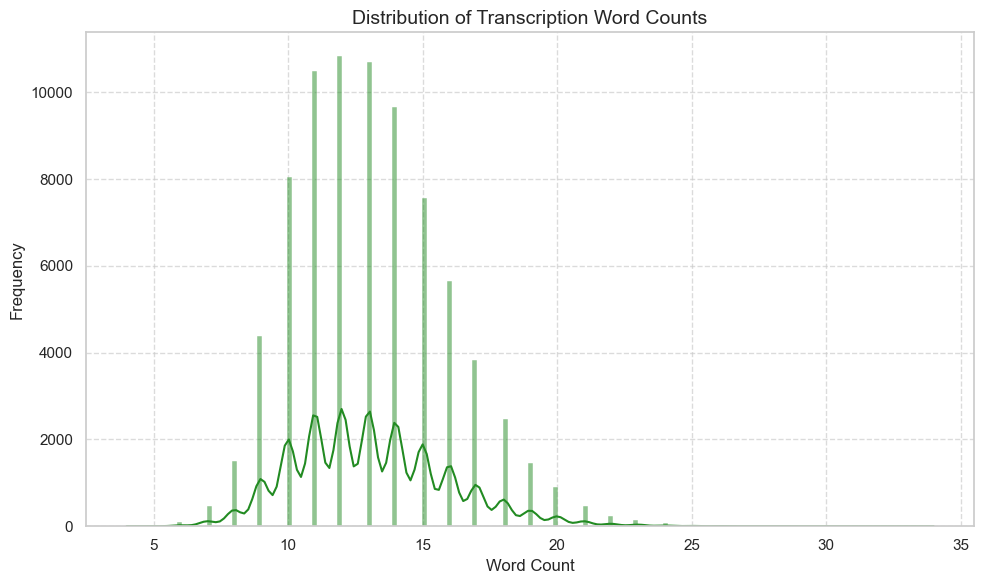

C:\Users\amari\AppData\Local\Temp\ipykernel_23900\3280772203.py:178: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=['Male', 'Female'])


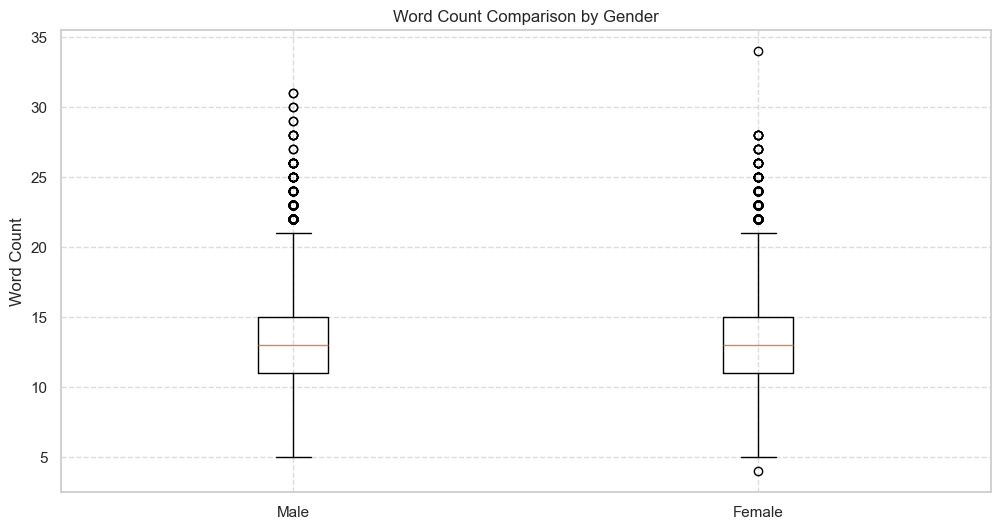


Average Word Count by Gender:
Male: 13.11 words
Female: 13.12 words

Analysis complete!


In [16]:

# Set the style for better visualizations
sns.set(style="whitegrid")

# Load the CSV file
df = pd.read_csv('dataset/validation.csv')

# Display basic information about the dataset
print(f"Dataset shape: {df.shape}")
print("\nFirst 5 rows:")
print(df.head())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Use regex pattern to find 'male' that's not part of 'female'
# This looks for 'male' that's either at a word boundary or has a specific prefix/suffix
male_pattern = r'(?<![fe])male\b|\bmale(?![s])|_male|male_'
female_pattern = r'female'

# Count files with 'male' and 'female' patterns
male_count = df['file_name'].str.lower().str.contains(male_pattern, regex=True).sum()
female_count = df['file_name'].str.lower().str.contains(female_pattern, regex=True).sum()

# Count specifically female
only_female_count = sum(df['file_name'].str.lower().str.contains(female_pattern, regex=True) & 
                        ~df['file_name'].str.lower().str.contains(male_pattern, regex=True))

# Count specifically male
only_male_count = sum(df['file_name'].str.lower().str.contains(male_pattern, regex=True) & 
                     ~df['file_name'].str.lower().str.contains(female_pattern, regex=True))

# Count files with both male and female patterns
both_mask = (df['file_name'].str.lower().str.contains(male_pattern, regex=True) & 
            df['file_name'].str.lower().str.contains(female_pattern, regex=True))
both_count = both_mask.sum()

# Get example filenames that contain both male and female patterns
both_examples = df[both_mask]['file_name'].head(5).tolist()

# Count files with neither male nor female patterns
neither_count = (~df['file_name'].str.lower().str.contains(male_pattern, regex=True) & 
                ~df['file_name'].str.lower().str.contains(female_pattern, regex=True)).sum()

print(f"\nFiles containing 'male': {male_count}")
print(f"Files containing 'female': {female_count}")
print(f"Files containing both 'male' and 'female': {both_count}")
print(f"Files containing neither 'male' nor 'female': {neither_count}")

# Display example filenames containing both 'male' and 'female'
if both_count > 0:
    print("\nExamples of filenames containing both 'male' and 'female':")
    for i, example in enumerate(both_examples, 1):
        print(f"{i}. {example}")
else:
    print("\nNo files found containing both 'male' and 'female'.")

# Create a more accurate gender distribution
gender_counts = {
    'Male': only_male_count,
    'Female': only_female_count,
}

# Calculate percentages
total = sum(gender_counts.values())
print("\nGender Distribution Percentages:")
for category, count in gender_counts.items():
    percentage = (count / total) * 100
    print(f"{category}: {percentage:.2f}%")

# Create an enhanced pie chart with 3D-like appearance
from matplotlib import cm

plt.figure(figsize=(12, 8))
ax = plt.subplot(111)

# Data preparation
labels = list(gender_counts.keys())
sizes = list(gender_counts.values())
total = sum(sizes)
percentages = [100 * s / total for s in sizes]

# Enhanced color palette - using a colormap for gradient effect
colors = cm.viridis(np.linspace(0.1, 0.9, len(sizes)))
explode = (0.1, 0.1)  # Explode all slices

# Creating the pie chart with 3D-like effects
wedges, texts, autotexts = ax.pie(
    sizes, 
    explode=explode,
    labels=labels, 
    colors=colors,
    autopct=lambda p: f'{p:.1f}%\n({int(p * total / 100)} files)',
    shadow=True,
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5, 'antialiased': True},
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

# Styling the autopct text
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(10)

# Setting the title with enhanced styling
plt.title('Gender Distribution in Speech Dataset', fontsize=18, fontweight='bold', pad=20)

# Adding a subtle background color
fig = plt.gcf()
fig.patch.set_facecolor('#f0f0f8')
ax.set_facecolor('#f8f8ff')

# Adding a legend with percentages
legend_labels = [f"{label}: {percentage:.1f}% ({int(percentage * total / 100)} files)" 
                for label, percentage in zip(labels, percentages)]
plt.legend(wedges, legend_labels, loc="center left", bbox_to_anchor=(1, 0, 0.5, 1), 
           fontsize=11, frameon=True, facecolor='#f8f8ff', edgecolor='gray')

# Add a circular boundary to enhance 3D effect
circle = plt.Circle((0, 0), 0.7, fc='white', fill=False, edgecolor='gray', linewidth=1)
ax.add_patch(circle)

# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# Final touches for better visualization
plt.tight_layout()

# Save the chart with higher quality
plt.savefig('gender_distribution_enhanced_pie_chart.png', dpi=300, bbox_inches='tight', 
            facecolor=fig.get_facecolor())

# Display the chart
plt.show()

# Additional EDA: Analyze transcription lengths
df['transcription_length'] = df['transcription'].str.len()
df['word_count'] = df['transcription'].str.split().str.len()

print("\nTranscription Statistics:")
print(df[['transcription_length', 'word_count']].describe())

# Create separate charts for transcription length analysis
# Chart 1: Distribution of Transcription Lengths (Characters)
plt.figure(figsize=(10, 6))
sns.histplot(df['transcription_length'], kde=True, color='steelblue')
plt.title('Distribution of Transcription Lengths (Characters)', fontsize=14)
plt.xlabel('Character Count', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('transcription_length_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 2: Distribution of Transcription Word Counts
plt.figure(figsize=(10, 6))
sns.histplot(df['word_count'], kde=True, color='forestgreen')
plt.title('Distribution of Transcription Word Counts', fontsize=14)
plt.xlabel('Word Count', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('transcription_word_count_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Analyze gender differences in transcription length (if applicable)
if male_count > 0 and female_count > 0:
    plt.figure(figsize=(12, 6))
    
    male_mask = df['file_name'].str.lower().str.contains(male_pattern, regex=True) & ~df['file_name'].str.lower().str.contains(female_pattern, regex=True)
    female_mask = df['file_name'].str.lower().str.contains(female_pattern, regex=True) & ~df['file_name'].str.lower().str.contains(male_pattern, regex=True)
    
    male_word_counts = df[male_mask]['word_count']
    female_word_counts = df[female_mask]['word_count']
    
    data_to_plot = [male_word_counts, female_word_counts]
    plt.boxplot(data_to_plot, labels=['Male', 'Female'])
    plt.title('Word Count Comparison by Gender')
    plt.ylabel('Word Count')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    plt.savefig('gender_word_count_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nAverage Word Count by Gender:")
    print(f"Male: {male_word_counts.mean():.2f} words")
    print(f"Female: {female_word_counts.mean():.2f} words")

print("\nAnalysis complete!")